<a href="https://colab.research.google.com/github/gloria-mbilinyi/gloria-mbilinyi-COU07506-labs/blob/main/COU07506_Week02_240242493088.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# WEEK 2 — LAB 1A: SAMPLING, ALIASING AND QUANTIZATION

**Student Name:** Gloria Beneth Mbilinyi
**Registration Number:** 240242493088
**Group: 8
**Module:** COU 07506 — Digital Signal Processing
**Academic Year:** 2026/2027

## Laboratory Objectives

1. Demonstrate aliasing in sampled signals.
2. Explain the purpose of anti-aliasing filters.
3. Implement a uniform quantizer.
4. Measure the signal-to-quantization-noise ratio (SQNR).
5. Verify the 6 dB-per-bit rule experimentally.

Task 2.1: Aliasing of a Sinusoid

Sampling rate: 10 Hz | Alias: 3.0 Hz
Sampling rate: 12 Hz | Alias: 5.0 Hz
Sampling rate: 14 Hz | Alias: 7.0 Hz
Sampling rate: 20 Hz | Alias: 7.0 Hz


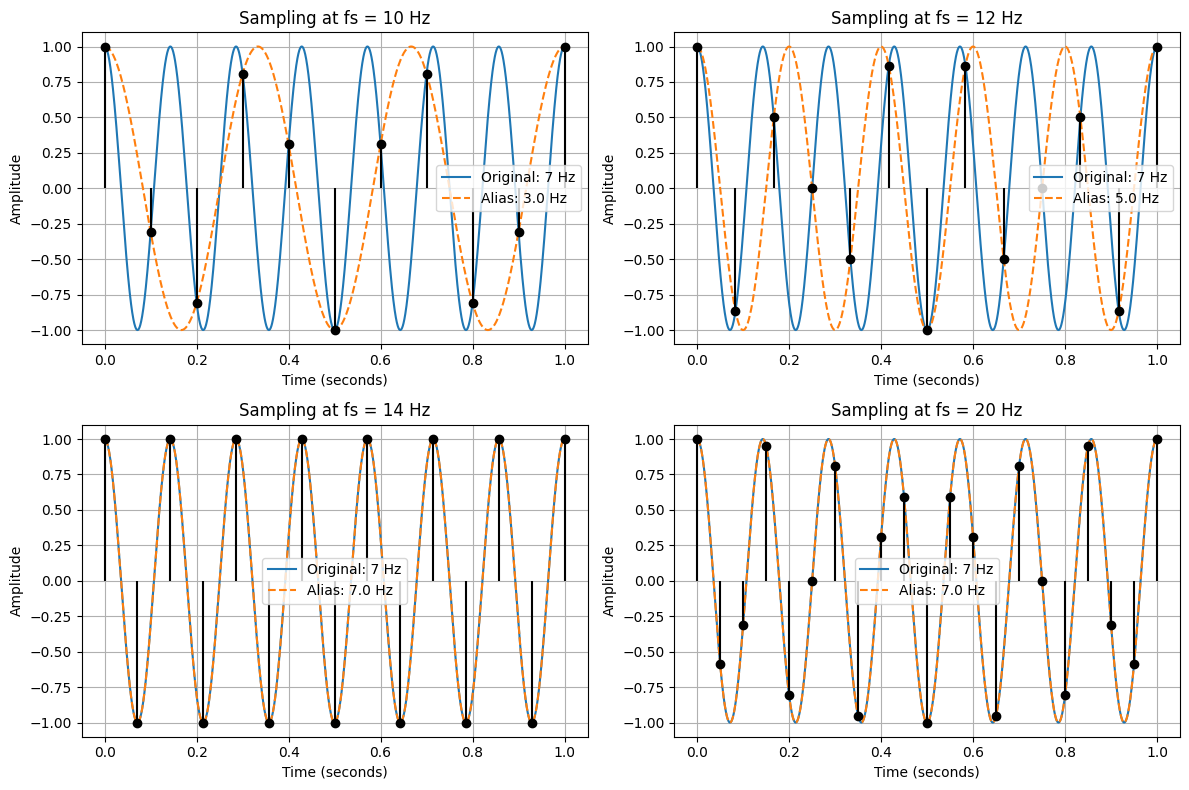

In [1]:

# Task 2.1: Aliasing of a Sinusoid

import numpy as np
import matplotlib.pyplot as plt

f0 = 7.0
sampling_rates = [10, 12, 14, 20]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, fs in zip(axes.flat, sampling_rates):

    t = np.linspace(0, 1, 2000)
    n = np.arange(0, int(fs) + 1)
    tn = n / fs

    f_alias = abs(f0 - fs * round(f0 / fs))

    ax.plot(t, np.cos(2*np.pi*f0*t),
            label="Original: 7 Hz")

    ax.plot(t, np.cos(2*np.pi*f_alias*t),
            "--", label=f"Alias: {f_alias} Hz")

    ax.stem(tn, np.cos(2*np.pi*f0*tn),
            linefmt="k-", markerfmt="ko",
            basefmt=" ")

    ax.set_title(f"Sampling at fs = {fs} Hz")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")
    ax.legend()
    ax.grid(True)

    print(f"Sampling rate: {fs} Hz | Alias: {f_alias} Hz")

plt.tight_layout()
plt.show()


### Task 2.1: Results and Discussion

A 7 Hz sinusoidal signal was sampled at four different sampling rates: 10 Hz, 12 Hz, 14 Hz, and 20 Hz.

At 10 Hz and 12 Hz, aliasing occurred, producing apparent frequencies of 3 Hz and 5 Hz respectively. At 14 Hz, the signal was sampled at the Nyquist rate, while at 20 Hz, the original frequency was preserved without aliasing.

The results demonstrate that selecting a suitable sampling frequency is important to avoid frequency distortion and accurately represent a signal.

**Task 2.2 — Hear Aliasing.**


In [2]:

from google.colab import files
import subprocess

# Upload original M4A recording
uploaded = files.upload()
filename = next(iter(uploaded))

# Convert to WAV and trim to 5 seconds
subprocess.run([
    "ffmpeg", "-y",
    "-i", filename,
    "-t", "5",
    "-ac", "1",
    "-ar", "44100",
    "my_voice_5sec.wav"
], check=True)

print("Audio converted successfully!")
print("Saved as: my_voice_5sec.wav")


Saving WhatsApp Audio 2026-11-23 at 21.38.20.mp4 to WhatsApp Audio 2026-11-23 at 21.38.20.mp4
Audio converted successfully!
Saved as: my_voice_5sec.wav


In [3]:

from google.colab import files

files.download("my_voice_5sec.wav")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:

# Task 2.2: Hear Aliasing

import numpy as np
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

# Load the 5-second voice recording
fs, x = wavfile.read("my_voice_5sec.wav")

# Convert to mono and normalize
if x.ndim > 1:
    x = x.mean(axis=1)

x = x.astype(float)
x = x / max(np.max(np.abs(x)), 1e-12)

print("Original sampling rate:", fs, "Hz")
print("Duration:", len(x) / fs, "seconds")

# Compare downsampling methods
for k in [2, 4, 8]:

    naive = x[::k]
    proper = signal.decimate(x, k, ftype="fir")

    new_fs = int(round(fs / k))

    print(f"\nDownsampling factor: {k}")
    print(f"New sampling rate: {fs/k} Hz")

    print("Without anti-aliasing filter:")
    display(Audio(naive, rate=new_fs))

    print("With anti-aliasing filter:")
    display(Audio(proper, rate=new_fs))


Original sampling rate: 44100 Hz
Duration: 4.999863945578231 seconds

Downsampling factor: 2
New sampling rate: 22050.0 Hz
Without anti-aliasing filter:


With anti-aliasing filter:



Downsampling factor: 4
New sampling rate: 11025.0 Hz
Without anti-aliasing filter:


With anti-aliasing filter:



Downsampling factor: 8
New sampling rate: 5512.5 Hz
Without anti-aliasing filter:


With anti-aliasing filter:


### Task 2.2: Results and Discussion

A five-second voice recording with an original sampling rate of 44,100 Hz was downsampled using factors of 2, 4, and 8.

Two methods were compared: direct downsampling without filtering and downsampling using an FIR anti-aliasing filter.

The resulting sampling rates were:

- **k = 2:** 22,050 Hz
- **k = 4:** 11,025 Hz
- **k = 8:** 5,512.5 Hz

Six audio outputs were successfully generated and played.

**Listening Observation:**

At a downsampling factor of 8, I observed that the second audio, which used an anti-aliasing filter, sounded clearer than the first audio without filtering.

The unfiltered recording contained more audible distortion, while the filtered version sounded clearer and smoother.

**Discussion:**

This result demonstrates the importance of anti-aliasing filters in digital signal processing. When a signal is downsampled without filtering, high-frequency components can fold into lower frequencies and produce distortion.

Applying an FIR low-pass filter before downsampling reduces these unwanted components and improves the quality of the resulting signal.

**Conclusion:**

The experiment demonstrated that anti-aliasing filtering is important when reducing the sampling rate of an audio signal.


**Task 2.3 — A Uniform Quantizer**


Sampling rate: 8000 Hz
Quantization bits: 3
Number of samples: 80
Quantization step: 0.25
Maximum absolute error: 0.24


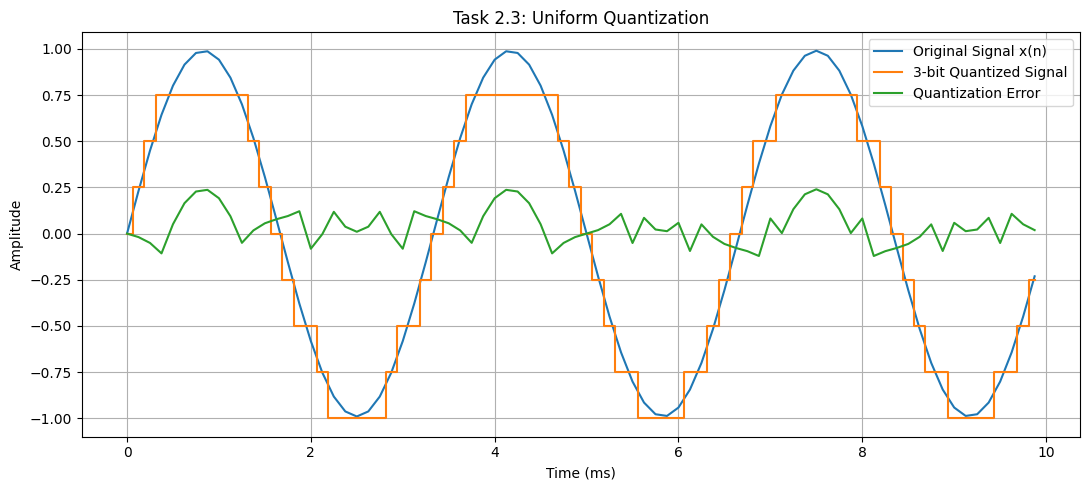

In [5]:

# Task 2.3: A Uniform Quantizer

import numpy as np
import matplotlib.pyplot as plt

# Define the uniform quantizer
def quantize(x, bits, full_scale=1.0):
    delta = 2 * full_scale / 2**bits
    q = np.round(x / delta) * delta
    return np.clip(q, -full_scale, full_scale - delta)

# Generate a sinusoidal signal
fs = 8000
t = np.arange(0, 0.01, 1/fs)
x = 0.99 * np.sin(2 * np.pi * 300 * t)

# Quantize the signal using 3 bits
xq = quantize(x, 3)

# Calculate quantization error
error = x - xq

# Display numerical results
print("Sampling rate:", fs, "Hz")
print("Quantization bits:", 3)
print("Number of samples:", len(x))
print("Quantization step:", 2 / 2**3)
print("Maximum absolute error:",
      np.max(np.abs(error)))

# Plot the signals
plt.figure(figsize=(11, 5))

plt.plot(t * 1000, x,
         label="Original Signal x(n)")

plt.step(t * 1000, xq,
         where="mid",
         label="3-bit Quantized Signal")

plt.plot(t * 1000, error,
         label="Quantization Error")

plt.title("Task 2.3: Uniform Quantization")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


### Task 2.3: Results and Discussion

A uniform 3-bit quantizer was implemented using Python to quantize a sinusoidal signal sampled at 8,000 Hz.

The experiment generated 80 samples with a quantization step size of 0.25 and a maximum absolute quantization error of 0.24.

The graph shows that the original signal has a smooth sinusoidal shape, while the quantized signal has a staircase appearance because its amplitude is restricted to discrete levels.

The quantization error represents the difference between the original and quantized signals. The largest error occurred near the positive peaks because the quantizer clips values above its maximum output level.

The experiment demonstrates that quantization approximates continuous-valued amplitudes using a limited number of levels, introducing quantization error.

**Task 2.4 — Verify the 6 dB-per-bit Rule**

Bits | Measured SQNR | Theoretical SQNR
--------------------------------------
   2 |         9.60 dB |        13.80 dB
   4 |        23.58 dB |        25.84 dB
   6 |        36.81 dB |        37.88 dB
   8 |        48.93 dB |        49.92 dB
  10 |        62.81 dB |        61.96 dB
  12 |        72.84 dB |        74.00 dB
  14 |        88.13 dB |        86.04 dB
  16 |        98.91 dB |        98.08 dB


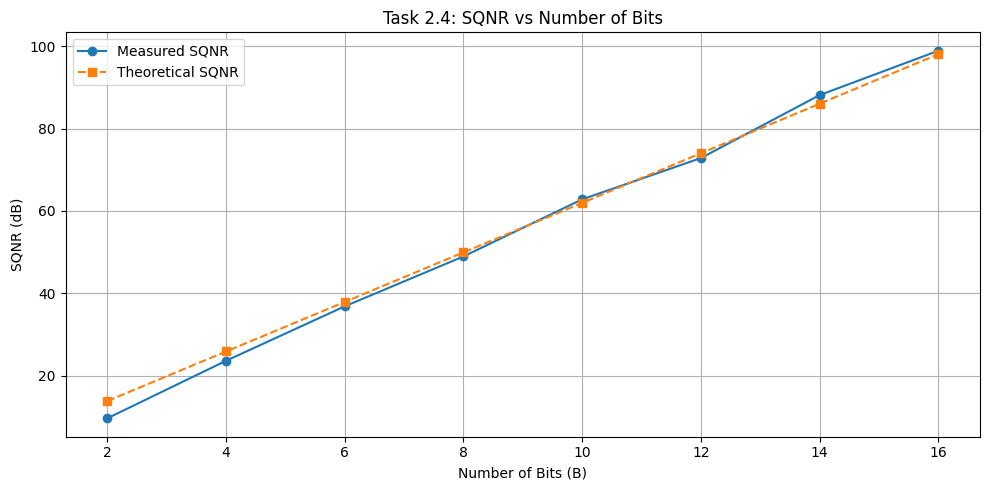

In [6]:

# Task 2.4: Verify the 6 dB-per-bit Rule

import numpy as np
import matplotlib.pyplot as plt

# Use the signal and quantize() function from Task 2.3

bits = np.arange(2, 17, 2)

# Calculate measured SQNR
meas = [
    10 * np.log10(
        np.sum(x**2) /
        np.sum((x - quantize(x, B))**2)
    )
    for B in bits
]

# Calculate theoretical SQNR
theory = 6.02 * bits + 1.76

# Display results
print("Bits | Measured SQNR | Theoretical SQNR")
print("--------------------------------------")

for B, m, th in zip(bits, meas, theory):
    print(f"{B:4d} | {m:12.2f} dB | {th:12.2f} dB")

# Plot results
plt.figure(figsize=(10, 5))

plt.plot(bits, meas, "o-", label="Measured SQNR")
plt.plot(bits, theory, "s--", label="Theoretical SQNR")

plt.title("Task 2.4: SQNR vs Number of Bits")
plt.xlabel("Number of Bits (B)")
plt.ylabel("SQNR (dB)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


### Task 2.4: Results and Discussion

The Signal-to-Quantization-Noise Ratio (SQNR) was calculated for different quantization bit depths ranging from 2 to 16 bits.

The graph shows that both measured and theoretical SQNR increase as the number of quantization bits increases. The measured values closely follow the theoretical curve, with small differences at certain bit depths.

The results demonstrate that increasing the number of quantization bits reduces quantization error and improves signal quality. The observed trend is consistent with the expected improvement of approximately 6 dB for every additional bit.

This experiment confirms the relationship between quantization resolution and SQNR.

**Task 2.5 — Quantize Your Voice**

In [7]:

# Task 2.5: Quantize Your Voice

import numpy as np
from scipy.io import wavfile
from IPython.display import Audio, display

# Load the 5-second voice recording
fs, voice = wavfile.read("my_voice_5sec.wav")

# Convert stereo to mono if necessary
if voice.ndim > 1:
    voice = voice.mean(axis=1)

# Normalize the voice recording
voice = voice.astype(float)
voice = voice / max(np.max(np.abs(voice)), 1e-12)

print("Original sampling rate:", fs, "Hz")
print("Recording duration:", round(len(voice)/fs, 2), "seconds")

# Quantize the voice at different bit depths
for B in [4, 8, 12]:

    # Use quantize() from Task 2.3
    voice_q = quantize(voice, B)

    # Calculate quantization error
    error = voice - voice_q

    # Calculate SQNR
    sqnr = 10 * np.log10(
        np.sum(voice**2) / np.sum(error**2)
    )

    print(f"\nQuantization bits: {B}")
    print(f"Measured SQNR: {sqnr:.2f} dB")

    # Listen to quantized audio
    display(Audio(voice_q, rate=fs))


Original sampling rate: 44100 Hz
Recording duration: 5.0 seconds

Quantization bits: 4
Measured SQNR: 16.35 dB



Quantization bits: 8
Measured SQNR: 40.27 dB



Quantization bits: 12
Measured SQNR: 64.36 dB


### Task 2.5: Results and Discussion

A five-second voice recording sampled at 44,100 Hz was quantized using 4-bit, 8-bit, and 12-bit resolutions.

The measured SQNR values were 16.35 dB, 40.27 dB, and 64.36 dB respectively.

The results show that increasing the number of quantization bits improves the Signal-to-Quantization-Noise Ratio. The 4-bit recording has the highest relative quantization error, while the 12-bit recording has the lowest.

The SQNR increased by approximately 24 dB for every additional four bits, which agrees with the expected improvement of about 6 dB per bit.

The measured SQNR values are lower than the theoretical values for a full-scale sine wave because speech has varying amplitude and includes quieter sections, so it does not continuously use the full quantizer range.

Overall, the experiment demonstrates that higher quantization resolution reduces quantization noise and provides a more accurate digital representation of the original voice signal.

### WEEK 2 — ANALYSIS QUESTIONS

**Question 1: Explain, with a frequency-axis sketch, why the 7 Hz tone appears at 3 Hz when the sampling frequency is 10 Hz.**

When a 7 Hz signal is sampled at 10 Hz, the Nyquist frequency is 5 Hz. Since the original signal frequency is above this limit, aliasing occurs.

The 7 Hz frequency folds back into the range below the Nyquist frequency and appears at 3 Hz.

In Task 2.1, the experimental result confirmed an alias frequency of 3 Hz. This demonstrates that sampling below the Nyquist rate can cause high-frequency components to appear as lower frequencies.

**Question 2: In Task 2.2, why can the aliasing heard in the naïve version not be removed afterwards?**

Aliasing cannot be completely removed after sampling because high-frequency components have already overlapped with lower-frequency components.

Once this happens, the original frequencies cannot be uniquely separated from the aliased frequencies.

In Task 2.2, I observed that the recording downsampled with an anti-aliasing filter sounded clearer than the recording downsampled without filtering at a factor of 8.

This shows why anti-aliasing filtering should be applied before downsampling.

**Question 3: By how much does the SQNR change when one bit is added? Does your measurement agree?**

The SQNR is expected to increase by approximately 6 dB for every additional quantization bit.

In Task 2.4, the measured SQNR increased as the number of bits increased, closely following the theoretical curve.

In Task 2.5, the recorded voice produced the following results:

- 4 bits: 16.35 dB
- 8 bits: 40.27 dB
- 12 bits: 64.36 dB

The measured improvement was approximately 24 dB for every four additional bits, equivalent to approximately 6 dB per bit.

Therefore, the experimental results agree with the expected relationship.

**Question 4: A temperature sensor changes by at most 0.1 °C per second, and the required resolution is 0.01 °C over a range of 0–100 °C. Suggest a sampling rate and number of bits, and justify them.**

A sampling rate of 10 samples per second (10 Hz) would be suitable for this temperature sensor.

Since the maximum temperature change is 0.1 °C per second, sampling at 10 Hz means the temperature changes by at most 0.01 °C between consecutive readings.

A 14-bit ADC would be appropriate because it provides 16,384 quantization levels, giving a temperature resolution of approximately 0.0061 °C across the 0–100 °C range.

This resolution is better than the required 0.01 °C.

Therefore, a sampling rate of 10 Hz and a 14-bit ADC would be a suitable choice for monitoring the temperature signal.

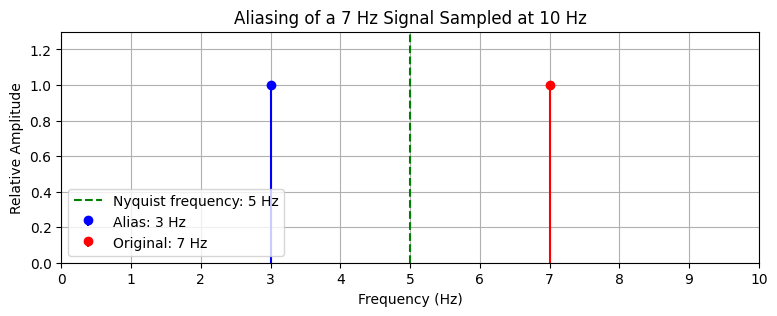

In [8]:

# Week 2 - Analysis Question 1
# Frequency-axis sketch demonstrating aliasing

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 3))

# Original and alias frequencies
plt.stem([3], [1], linefmt='b-', markerfmt='bo',
         basefmt=' ', label='Alias: 3 Hz')

plt.stem([7], [1], linefmt='r-', markerfmt='ro',
         basefmt=' ', label='Original: 7 Hz')

# Nyquist frequency
plt.axvline(5, color='green', linestyle='--',
            label='Nyquist frequency: 5 Hz')

plt.xlim(0, 10)
plt.ylim(0, 1.3)
plt.xticks(range(0, 11))
plt.xlabel('Frequency (Hz)')
plt.ylabel('Relative Amplitude')
plt.title('Aliasing of a 7 Hz Signal Sampled at 10 Hz')
plt.legend()
plt.grid(True)

plt.show()


**Analysis Question 1 — Frequency-Axis Sketch**

The frequency-axis sketch shows an original signal at 7 Hz and its alias at 3 Hz when sampled at 10 Hz.

The Nyquist frequency is 5 Hz. Since the original frequency exceeds this limit, it folds into the lower-frequency range, appearing at 3 Hz.

The sketch confirms the aliasing result obtained in Task 2.1.

### CONCLUSION

In this laboratory, I investigated sampling, aliasing, and quantization using Python in Google Colab.

The aliasing experiment demonstrated how insufficient sampling rates cause frequency distortion. The audio experiment showed that applying an anti-aliasing filter before downsampling can improve the quality of the resulting signal.

Uniform quantization was also implemented, and the relationship between quantization bits and SQNR was examined. The measured results showed that increasing the number of bits reduces quantization error and improves signal quality.

Overall, the laboratory improved my understanding of sampling theory, anti-aliasing filtering, quantization, and their applications in digital audio processing.

### AI-USE STATEMENT

I used ChatGPT to assist with understanding the laboratory instructions, explaining Python code, troubleshooting, and interpreting the results.

I verified the outputs by executing the programs in Google Colab, examining the generated graphs, checking numerical results, and listening to the processed audio recordings.